=== Running Recursive Mode Training ===
[Ep 001] Round  500 | Alive  48 | E_tot 44.7J | PDR 1.0000 | Reward 90.57
[Ep 001] Round 1000 | Alive  29 | E_tot 15.5J | PDR 1.0000 | Reward 71.40
[Ep 001] Round 1500 | Alive  10 | E_tot 3.0J | PDR 1.0000 | Reward 66.91

=== Recursive Episode 1/10 Summary ===
Length (rounds): 1992
FND: 120 | HND: 437 | LND: 1992
Average PDR: 0.9995
Episode Return: 161082.29
Agent epsilon: 0.560578034937554
[Ep 002] Round  500 | Alive  47 | E_tot 46.7J | PDR 1.0000 | Reward 89.87
[Ep 002] Round 1000 | Alive  30 | E_tot 16.5J | PDR 1.0000 | Reward 77.95
[Ep 002] Round 1500 | Alive  11 | E_tot 4.1J | PDR 1.0000 | Reward 54.65
[Ep 002] Round 2000 | Alive   2 | E_tot 0.2J | PDR 1.0000 | Reward 60.52

=== Recursive Episode 2/10 Summary ===
Length (rounds): 2109
FND: 110 | HND: 482 | LND: 2109
Average PDR: 0.9995
Episode Return: 169830.10
Agent epsilon: 0.29772597980804744
[Ep 003] Round  500 | Alive  48 | E_tot 46.4J | PDR 1.0000 | Reward 85.55
[Ep 003] Round 1000 | A

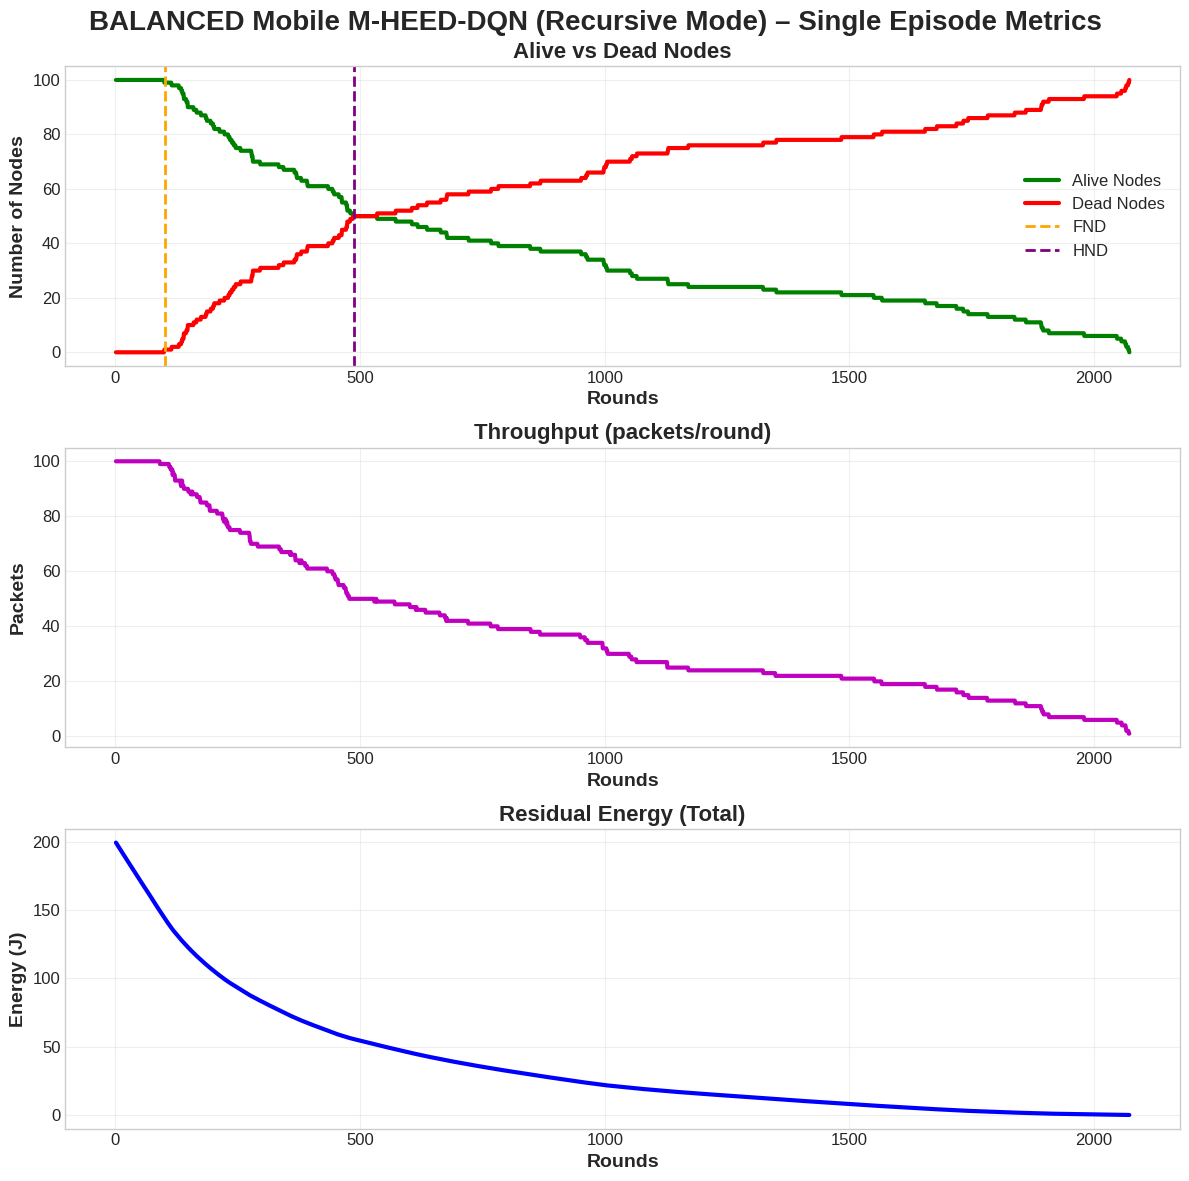

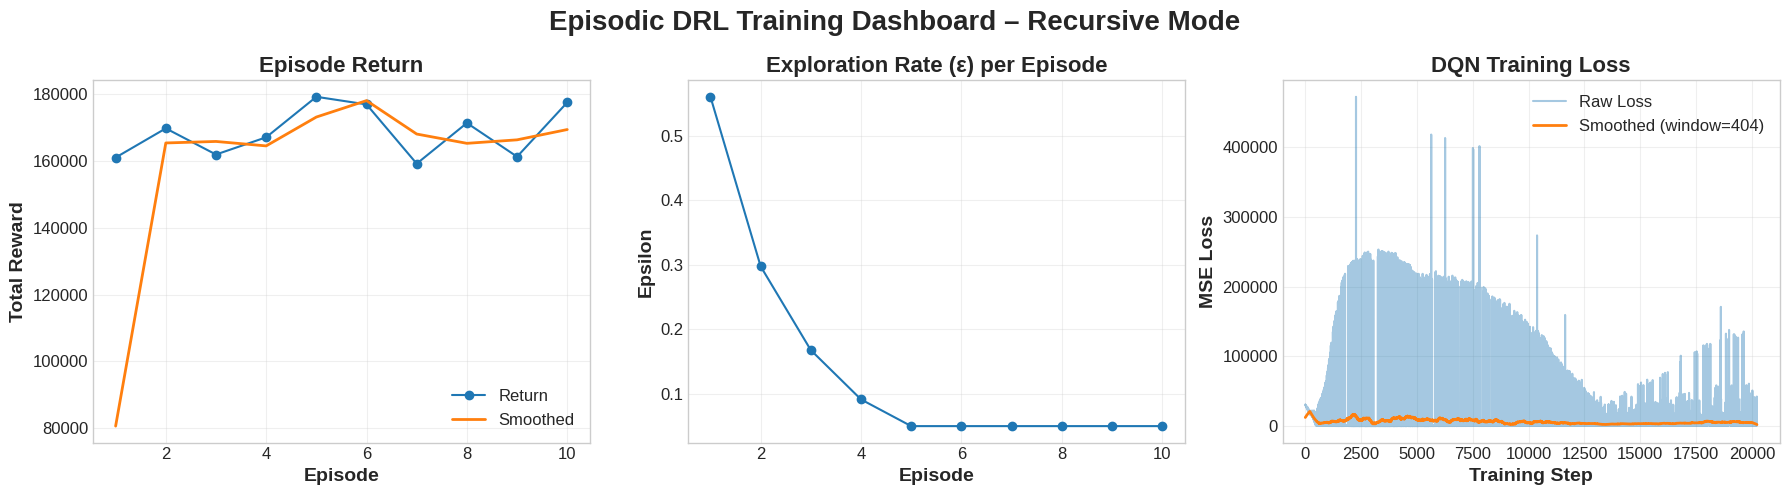


SUMMARY TABLE: Recursive Mode
                   Metric  Recursive Mode
                      FND      101.000000
                      HND      487.000000
                      LND     2072.000000
              Average PDR        0.999517
           Episode Return   177620.774964
Final Residual Energy (J)        0.000000
 Avg Energy Balance (σ/μ)        0.384936


In [2]:
"""
BALANCED Mobile Multi-Level M-HEED + DQN (Episodic Version, RECURSIVE MODE)
Target: FND > 1400, HND > 2300, PDR ≥ 0.97
Episodic DRL: Each episode = one full network lifetime (until all nodes die or max rounds).
"""

import numpy as np
import random
from collections import deque

from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import pandas as pd  # for summary table

# -------------------- PyTorch (optional) --------------------
try:
    import torch  # type: ignore
    import torch.nn as nn  # type: ignore
    import torch.optim as optim  # type: ignore
    import torch.nn.functional as F  # type: ignore
    TORCH_AVAILABLE = True
except ImportError:
    torch = None  # type: ignore
    optim = None  # type: ignore
    F = None  # type: ignore
    TORCH_AVAILABLE = False

# ============================================================
#                       PARAMETERS
# ============================================================
Nodes = 100
Area = 200
Sink = np.array([100.0, 250.0])
E0 = 2.0
L_data = 4000
Rounds = 4000          # Maximum rounds per episode
Eelec = 50e-9
Efs = 10e-12
Emp = 0.0013e-12
EDA = 5e-9
d0 = 87.0
v_max = 0.8

# DRL Hyperparameters
state_dim = 10
action_dim = 5
hidden = 256
lr = 2e-4
gamma = 0.99
epsilon_start = 1.0
epsilon_end = 0.05
epsilon_decay = 0.9997
buffer_size = 100000
batch_size = 64
target_update = 10

# Energy thresholds
E_RESERVE = 0.01       # 10 mJ minimum reserve (below this = dead)
E_CRITICAL = 0.05      # Critical threshold for CH selection
IDLE_COST = 5e-4       # Small idle cost per round (J) to drain “stuck” nodes

np.random.seed(42)
random.seed(42)
if TORCH_AVAILABLE:
    torch.manual_seed(42)


# ============================================================
#                           NODE
# ============================================================
class Node:
    """Represents a mobile sensor node with energy and mobility attributes."""
    __slots__ = ['x', 'y', 'prev_x', 'prev_y', 'E', 'alive', 'ch_count', 'tx_count']

    def __init__(self, x, y):
        self.x = self.prev_x = x
        self.y = self.prev_y = y
        self.E = E0
        self.alive = True
        self.ch_count = 0
        self.tx_count = 0  # Track transmission load


# ============================================================
#                           DQN
# ============================================================
if TORCH_AVAILABLE:
    class DQN(nn.Module):
        """Deep Q-Network approximator using PyTorch."""

        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(state_dim, hidden), nn.ReLU(),
                nn.Linear(hidden, hidden), nn.ReLU(),
                nn.Linear(hidden, hidden // 2), nn.ReLU(),
                nn.Linear(hidden // 2, action_dim)
            )

        def forward(self, x):
            return self.net(x)
else:
    class DQN:
        """Fallback stub when PyTorch is unavailable."""
        def __init__(self):
            raise RuntimeError("DQN cannot be instantiated without PyTorch")

        def forward(self, x):
            raise RuntimeError("DQN cannot be used without PyTorch")


# ============================================================
#                           AGENT
# ============================================================
class Agent:
    """Agent controlling clustering parameters (DQN + heuristic fallback)."""

    def __init__(self):
        # Predefined configurations: (p_init, ch_ratio_target, Tr1, Tr2)
        self.configs = [
            (0.03, 0.25, 30, 65),
            (0.05, 0.40, 40, 80),
            (0.07, 0.55, 50, 95),
            (0.09, 0.70, 60, 110),
            (0.11, 0.85, 70, 125)
        ]

        if TORCH_AVAILABLE:
            self.dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            self.policy = DQN().to(self.dev)
            self.target = DQN().to(self.dev)
            self.target.load_state_dict(self.policy.state_dict())
            self.target.eval()
            self.opt = optim.Adam(self.policy.parameters(), lr=lr)
            self.buffer = deque(maxlen=buffer_size)
            self.epsilon = epsilon_start
            self.steps = 0
            self.loss_values = []
        else:
            # Heuristic fallback: fixed aggressive configuration
            self.default_action = 4

    def state(self, nodes, rnd, ch_cnt, avg_hop, E_std_ratio):
        """Build normalized state vector from current network state."""
        alive = [n for n in nodes if n.alive]
        n = len(alive)
        if n == 0:
            return np.zeros(state_dim, dtype=np.float32)

        E = np.array([nd.E for nd in alive])
        pos = np.array([[nd.x, nd.y] for nd in alive])
        dists = pdist(pos) if n > 1 else np.array([0.0])
        move = np.mean([np.hypot(nd.x - nd.prev_x, nd.y - nd.prev_y) for nd in alive])

        return np.array([
            n / Nodes,
            E.mean() / E0,
            E.min() / E0,
            E.max() / E0,
            E_std_ratio,
            dists.mean() / 200.0,
            np.clip(move / v_max, 0.0, 1.0),
            ch_cnt / max(n, 1),
            avg_hop / 5.0,
            rnd / Rounds
        ], dtype=np.float32)

    def act(self, s):
        """Select an action. When DQN is unavailable, return a heuristic choice."""
        if TORCH_AVAILABLE:
            if random.random() < self.epsilon:
                return random.randrange(action_dim)
            with torch.no_grad():
                q = self.policy(torch.FloatTensor(s).unsqueeze(0).to(self.dev))
                return q.argmax(1).item()
        else:
            return int(self.default_action)

    def config(self, a):
        return self.configs[a]

    def store(self, s, a, r, s2):
        if TORCH_AVAILABLE:
            self.buffer.append((s, a, r, s2))

    def train_step(self):
        """Single DQN training step using replay buffer.
        Returns the scalar loss value (float) when a gradient update happens, else None.
        """
        if not TORCH_AVAILABLE or len(self.buffer) < batch_size:
            return None

        batch = random.sample(self.buffer, batch_size)
        s, a, r, s2 = map(np.array, zip(*batch))
        s = torch.FloatTensor(s).to(self.dev)
        a = torch.LongTensor(a).unsqueeze(1).to(self.dev)
        r = torch.FloatTensor(r).unsqueeze(1).to(self.dev)
        s2 = torch.FloatTensor(s2).to(self.dev)

        Q = self.policy(s).gather(1, a)
        with torch.no_grad():
            Q_next = self.target(s2).max(1)[0].unsqueeze(1)
            target_q = r + gamma * Q_next

        loss = F.mse_loss(Q, target_q)
        self.opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy.parameters(), 1.0)
        self.opt.step()

        loss_val = float(loss.item())
        self.loss_values.append(loss_val)

        # Epsilon decay
        self.epsilon = max(epsilon_end, self.epsilon * epsilon_decay)
        self.steps += 1

        # Target network update
        if self.steps % target_update == 0:
            self.target.load_state_dict(self.policy.state_dict())

        return loss_val

    @staticmethod
    def reward(alive, delivered, pdr, ch_ratio, E_min, E_std_ratio, avg_hop):
        """
        Reward = network health score at this round.
        Re-weighted to prioritize lifetime (alive, min energy) more than PDR.
        """
        target_ch = 0.07
        r_alive   = (alive / Nodes) ** 1.5
        r_pdr     = pdr ** 1.5
        r_ch      = max(0, 1.0 - 8.0 * abs(ch_ratio - target_ch))
        r_min_e   = (E_min / E0) ** 0.8
        r_balance = 1.0 / (1.0 + 5.0 * E_std_ratio)
        r_hop     = max(0, 1.0 - avg_hop / 5.0)

        # Emphasis: lifetime and minimum energy
        return 200.0 * (0.40 * r_alive +
                        0.20 * r_pdr +
                        0.10 * r_ch +
                        0.20 * r_min_e +
                        0.07 * r_balance +
                        0.03 * r_hop)


# ============================================================
#                    ENVIRONMENT HELPERS
# ============================================================
def clustering(alive_list, p_init, rnd):
    """Select Level-1 cluster heads and assign members with load balancing."""
    if len(alive_list) <= 1:
        idx = [i for i, _ in alive_list]
        return idx, {i: [i] for i in idx}

    idxs = [i for i, _ in alive_list]
    nodes = [n for _, n in alive_list]
    n = len(nodes)

    E = np.array([nd.E for nd in nodes])
    pos = np.array([[nd.x, nd.y] for nd in nodes])
    vel = np.array([np.hypot(nd.x - nd.prev_x, nd.y - nd.prev_y) for nd in nodes])
    ch_cnt = np.array([nd.ch_count for nd in nodes])
    tx_cnt = np.array([nd.tx_count for nd in nodes])

    # Normalize energy (critical nodes get protection)
    E_norm = E / E.max()
    E_protected = np.where(E < E_CRITICAL, 0.0, E_norm)

    # Mobility factor
    fmob = 1.0 / (1.0 + 2.0 * vel)

    # Load balancing factors
    frot = 1.0 / (1.0 + 0.4 * ch_cnt)   # CH rotation
    fload = 1.0 / (1.0 + 0.3 * tx_cnt)  # Transmission load balancing

    # Distance to sink
    dist_sink = np.array([np.hypot(nd.x - Sink[0], nd.y - Sink[1]) for nd in nodes])
    fsink = 1.0 / (1.0 + dist_sink / 150.0)

    # Centrality
    D = squareform(pdist(pos))
    np.fill_diagonal(D, np.inf)
    avg_dist = np.mean(np.where(D < np.inf, D, 0), axis=1)
    fcent = 1.0 - (avg_dist - avg_dist.min()) / (avg_dist.max() - avg_dist.min() + 1e-12)

    prob = np.clip(
        p_init * (E_protected ** 1.5) * fmob * frot * fload * (fsink ** 0.6) * (fcent ** 0.3),
        0.01, 0.95
    )

    is_ch = np.zeros(n, dtype=bool)
    for _ in range(6):
        is_ch |= np.random.rand(n) < prob
        prob = np.clip(prob * 1.3, 0.0, 1.0)

    # Ensure we have CHs
    if not is_ch.any():
        safe_nodes = np.where(E > E_CRITICAL)[0]
        if len(safe_nodes) > 0:
            scores = E[safe_nodes] * fmob[safe_nodes] * fsink[safe_nodes]
            best_idx = safe_nodes[np.argmax(scores)]
        else:
            best_idx = np.argmax(E)
        is_ch[best_idx] = True

    ch_local = np.where(is_ch)[0]
    ch_global = [idxs[i] for i in ch_local]

    # Update CH count
    for i in ch_local:
        nodes[i].ch_count += 1

    # Load-balanced member assignment
    members = {ch: [] for ch in ch_global}
    for i, gid in enumerate(idxs):
        if gid in ch_global:
            members[gid].append(gid)
            continue

        ch_loads = [len(members[idxs[j]]) for j in ch_local]
        dists = [np.hypot(nodes[i].x - nodes[j].x, nodes[i].y - nodes[j].y) for j in ch_local]

        scores = []
        for d, load in zip(dists, ch_loads):
            load_penalty = 1.0 + 0.2 * load
            scores.append(d * load_penalty)

        nearest = ch_local[np.argmin(scores)]
        members[idxs[nearest]].append(gid)

    return ch_global, members


def move(nodes):
    """Randomly move alive nodes within the area."""
    for n in nodes:
        if n.alive:
            n.prev_x, n.prev_y = n.x, n.y
            dx = random.uniform(-v_max, v_max)
            dy = random.uniform(-v_max, v_max)
            n.x = np.clip(n.x + dx, 0, Area)
            n.y = np.clip(n.y + dy, 0, Area)


def tx_cost(d):
    """Transmission energy cost for distance d."""
    if d <= d0:
        return L_data * (Eelec + Efs * d * d)
    else:
        return L_data * (Eelec + Emp * d ** 4)


def reset_nodes():
    """Create a fresh network for a new episode."""
    return [Node(x, y) for x, y in np.random.uniform(0, Area, (Nodes, 2))]


# ============================================================
#                       ONE EPISODE
# ============================================================
def run_episode(agent, episode_idx=0, max_rounds=Rounds):
    """
    Run ONE episode = full network lifetime (RECURSIVE MODE).
    Returns:
        log: per-round metrics for this episode
        episode_return: sum of rewards over the episode
        episode_len: number of rounds in this episode
    """
    nodes = reset_nodes()
    prev_s = np.zeros(state_dim, dtype=np.float32)
    prev_a = 0

    log = {'alive': [], 'energy': [], 'thr': [], 'pdr': [], 'rwd': [], 'e_std': []}
    fnd = hnd = None
    episode_return = 0.0
    prev_alive = Nodes  # For death-penalty calculation

    for rnd in range(max_rounds):
        move(nodes)
        alive_idx = [i for i, n in enumerate(nodes) if n.alive]
        n_alive = len(alive_idx)

        if n_alive == 0:
            # All nodes dead -> terminal
            break

        if n_alive < Nodes and fnd is None:
            fnd = rnd + 1
        if n_alive <= Nodes // 2 and hnd is None:
            hnd = rnd + 1

        E_alive = [nodes[i].E for i in alive_idx]
        E_std_ratio = np.std(E_alive) / (np.mean(E_alive) + 1e-9)

        # Build state and choose action
        s = agent.state(nodes, rnd, ch_cnt=10, avg_hop=3.0, E_std_ratio=E_std_ratio)
        a = agent.act(s)
        p_init, _, Tr1, Tr2 = agent.config(a)  # Tr1 kept for extensibility

        # ---------------- Level-1 clustering ----------------
        L1_CHs, members = clustering([(i, nodes[i]) for i in alive_idx], p_init, rnd)

        # ---------------- Level-2 recursive super-CH formation ----------------
        # Build a parent map among L1_CHs using recursive grouping with Tr2
        parent = {ch: ch for ch in L1_CHs}
        remaining = L1_CHs[:]

        while remaining:
            seed = remaining[0]
            # Group CHs within Tr2 of the seed (recursive grouping region)
            cluster = [c for c in remaining
                       if np.hypot(nodes[seed].x - nodes[c].x,
                                   nodes[seed].y - nodes[c].y) <= Tr2]

            # Among this local cluster, pick an energy/sink-biased super-CH
            scores = []
            for c in cluster:
                if nodes[c].E < E_CRITICAL:
                    scores.append(0.0)
                else:
                    d_sink = np.hypot(nodes[c].x - Sink[0], nodes[c].y - Sink[1])
                    score = (nodes[c].E / E0) / (1.0 + d_sink / 100.0)
                    scores.append(score)

            if max(scores) > 0:
                super_ch = cluster[np.argmax(scores)]
            else:
                super_ch = cluster[0]

            for c in cluster:
                parent[c] = super_ch

            # Remove processed cluster from remaining list
            remaining = [x for x in remaining if x not in cluster]

        # Root super-CHs: those whose parent is themselves become direct sink children
        for ch in L1_CHs:
            if parent[ch] == ch:
                parent[ch] = -1

        # ---------------- Transmission phase with recursive routing ----------------
        delivered = 0
        attempts = 0
        energy_used = 0.0
        hop_counts = []

        # Sort by energy so heavy-energy nodes carry more load early
        tx_order = sorted(alive_idx, key=lambda i: nodes[i].E, reverse=True)

        for i in tx_order:
            # Skip nodes at or below reserve (treated as effectively dead for tx)
            if (not nodes[i].alive) or (nodes[i].E <= E_RESERVE):
                continue

            cur = i
            path_cost = 0.0
            hops = []
            hop_count = 0
            valid_path = True

            # Recursive forwarding: node -> CH -> super-CH -> ... -> sink
            while cur != -1 and valid_path:
                nxt = parent.get(cur, -1)
                if nxt == -1:
                    d = np.hypot(nodes[cur].x - Sink[0], nodes[cur].y - Sink[1])
                else:
                    d = np.hypot(nodes[cur].x - nodes[nxt].x, nodes[cur].y - nodes[nxt].y)

                cost = tx_cost(d)

                # Must be able to pay tx cost AND keep reserve
                if nodes[cur].E < cost + E_RESERVE:
                    valid_path = False
                    break

                path_cost += cost
                hops.append((cur, nxt, d, cost))
                hop_count += 1
                cur = nxt

            # Aggregation cost at non-CH members
            agg_cost = L_data * EDA if i not in L1_CHs else 0.0
            path_cost += agg_cost

            # Check if source node can pay its share + reserve
            if valid_path and nodes[i].E >= path_cost + E_RESERVE:
                attempts += 1
                for cur, nxt, d, cost in hops:
                    nodes[cur].E -= cost
                    energy_used += cost
                    nodes[cur].tx_count += 1
                    if nxt == -1:
                        # Final hop to sink includes data aggregation at CH
                        nodes[cur].E -= L_data * EDA
                        energy_used += L_data * EDA
                if agg_cost > 0:
                    nodes[i].E -= agg_cost
                    energy_used += agg_cost
                delivered += 1
                hop_counts.append(hop_count)

        # ---------- Idle drain to avoid “stuck” nodes ----------
        for n in nodes:
            if n.alive and n.E > 0.0:
                n.E = max(0.0, n.E - IDLE_COST)

        # Mark dead nodes (at or below reserve)
        for n in nodes:
            if n.E <= E_RESERVE and n.alive:
                n.alive = False
                n.E = 0.0

        n_alive = sum(1 for n in nodes if n.alive)
        dead_this_round = max(0, prev_alive - n_alive)
        prev_alive = n_alive

        # Recompute metrics for reward and logging
        if n_alive == 0:
            pdr = 0.0
            ch_ratio = 0.0
            E_min = 0.0
            avg_hop = 5.0
            E_std_ratio = 0.0
        else:
            alive_idx = [i for i, n in enumerate(nodes) if n.alive]
            E_alive = [nodes[i].E for i in alive_idx]
            E_std_ratio = np.std(E_alive) / (np.mean(E_alive) + 1e-9)

            pdr = delivered / max(attempts, 1)
            ch_ratio = len(L1_CHs) / max(n_alive, 1)
            E_min = min(E_alive) if E_alive else 0.0
            avg_hop = np.mean(hop_counts) if hop_counts else 5.0

        # Base reward
        rwd = Agent.reward(n_alive, delivered, pdr, ch_ratio, E_min, E_std_ratio, avg_hop)

        # Explicit death penalty
        death_penalty = 80.0 * (dead_this_round / Nodes)
        rwd -= death_penalty

        episode_return += rwd

        # Next state (recursive dependency on CH structure & hop stats)
        s2 = agent.state(nodes, rnd + 1, len(L1_CHs), avg_hop, E_std_ratio)

        # Store and train
        agent.store(prev_s, prev_a, rwd, s2)
        agent.train_step()
        prev_s, prev_a = s, a

        # Logging
        log['alive'].append(n_alive)
        log['energy'].append(sum(nd.E for nd in nodes))
        log['thr'].append(delivered)
        log['pdr'].append(pdr)
        log['rwd'].append(rwd)
        log['e_std'].append(E_std_ratio)

        if (rnd + 1) % 500 == 0:
            print(f"[Ep {episode_idx+1:03d}] Round {rnd+1:4d} | "
                  f"Alive {n_alive:3d} | E_tot {log['energy'][-1]:.1f}J | "
                  f"PDR {pdr:.4f} | Reward {rwd:.2f}")

    episode_len = len(log['alive'])
    FND = fnd or episode_len
    HND = hnd or episode_len
    LND = episode_len  # last round of this episode

    log['FND'] = FND
    log['HND'] = HND
    log['LND'] = LND

    return log, episode_return, episode_len


# ============================================================
#                     TRAINING LOOP (EPISODIC)
# ============================================================
def train_drl_recursive(num_episodes=20):
    """Train the DQN agent in RECURSIVE MODE over multiple episodes (network lifetimes)."""
    agent = Agent()
    history = {
        'episode_return': [],
        'episode_len': [],
        'FND': [],
        'HND': [],
        'LND': [],
        'avg_PDR': [],
        'epsilon': [],
        'loss_values': [],
        'last_log': None
    }

    for ep in range(num_episodes):
        log, ep_ret, ep_len = run_episode(agent, episode_idx=ep, max_rounds=Rounds)
        history['episode_return'].append(ep_ret)
        history['episode_len'].append(ep_len)
        history['FND'].append(log['FND'])
        history['HND'].append(log['HND'])
        history['LND'].append(log['LND'])
        history['avg_PDR'].append(float(np.mean(log['pdr'])))
        history['last_log'] = log
        history['epsilon'].append(getattr(agent, 'epsilon', None))

        print(f"\n=== Recursive Episode {ep+1}/{num_episodes} Summary ===")
        print(f"Length (rounds): {ep_len}")
        print(f"FND: {log['FND']} | HND: {log['HND']} | LND: {log['LND']}")
        print(f"Average PDR: {np.mean(log['pdr']):.4f}")
        print(f"Episode Return: {ep_ret:.2f}")
        print(f"Agent epsilon: {getattr(agent, 'epsilon', None)}")
        print("=" * 60)

    # Copy loss history from agent
    if TORCH_AVAILABLE and hasattr(agent, 'loss_values'):
        history['loss_values'] = list(agent.loss_values)
    else:
        history['loss_values'] = []

    return history


# ============================================================
#                          PLOTTING
# ============================================================
def plot_episode(log):
    """
    Plot per-round metrics for a single episode (typically last one).
    Shows ONLY three plots:
      1) Alive vs Dead nodes
      2) Throughput
      3) Residual Energy
    """
    r = np.arange(1, len(log['alive']) + 1)
    alive = np.array(log['alive'])
    dead = Nodes - alive

    plt.style.use('seaborn-v0_8-whitegrid')

    fig, ax = plt.subplots(3, 1, figsize=(12, 12))
    fig.suptitle('BALANCED Mobile M-HEED-DQN (Recursive Mode) – Single Episode Metrics',
                 fontsize=20, fontweight='bold')

    # ---------- 1) Alive vs Dead ----------
    ax[0].plot(r, alive, 'g-', lw=3, label='Alive Nodes')
    ax[0].plot(r, dead,  'r-', lw=3, label='Dead Nodes')

    ax[0].axvline(log['FND'], color='orange', ls='--', lw=2, label='FND')
    ax[0].axvline(log['HND'], color='purple', ls='--', lw=2, label='HND')

    ax[0].set_title('Alive vs Dead Nodes', fontsize=16, fontweight='bold')
    ax[0].set_xlabel('Rounds', fontsize=14, fontweight='bold')
    ax[0].set_ylabel('Number of Nodes', fontsize=14, fontweight='bold')
    ax[0].tick_params(axis='both', labelsize=12)
    ax[0].legend(fontsize=12)
    ax[0].grid(alpha=0.3)

    # ---------- 2) Throughput ----------
    ax[1].plot(r, log['thr'], 'm-', lw=3)
    ax[1].set_title('Throughput (packets/round)', fontsize=16, fontweight='bold')
    ax[1].set_xlabel('Rounds', fontsize=14, fontweight='bold')
    ax[1].set_ylabel('Packets', fontsize=14, fontweight='bold')
    ax[1].tick_params(axis='both', labelsize=12)
    ax[1].grid(alpha=0.3)

    # ---------- 3) Residual Energy ----------
    ax[2].plot(r, log['energy'], 'b-', lw=3)
    ax[2].set_title('Residual Energy (Total)', fontsize=16, fontweight='bold')
    ax[2].set_xlabel('Rounds', fontsize=14, fontweight='bold')
    ax[2].set_ylabel('Energy (J)', fontsize=14, fontweight='bold')
    ax[2].tick_params(axis='both', labelsize=12)
    ax[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_training_dashboard(history):
    """
    Multi-panel DRL Training Dashboard (Recursive Mode):
      - Episode return vs episode
      - Epsilon vs episode
      - Training loss vs gradient step
    """
    episodes = np.arange(1, len(history['episode_return']) + 1)
    returns = np.array(history['episode_return'], dtype=float)
    eps = np.array(history['epsilon'], dtype=float)
    losses = np.array(history.get('loss_values', []), dtype=float)

    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Episodic DRL Training Dashboard – Recursive Mode',
                 fontsize=20, fontweight='bold')

    # -------- Panel 1: Episode Return --------
    if len(returns) > 0:
        ax[0].plot(episodes, returns, marker='o', label='Return')
        window = max(1, len(returns) // 5)
        smooth_ret = np.convolve(returns, np.ones(window) / window, mode='same')
        ax[0].plot(episodes, smooth_ret, linewidth=2, label='Smoothed')
    ax[0].set_title('Episode Return', fontsize=16, fontweight='bold')
    ax[0].set_xlabel('Episode', fontsize=14, fontweight='bold')
    ax[0].set_ylabel('Total Reward', fontsize=14, fontweight='bold')
    ax[0].tick_params(axis='both', labelsize=12)
    ax[0].grid(alpha=0.3)
    ax[0].legend(fontsize=12)

    # -------- Panel 2: Epsilon Decay --------
    if len(eps) > 0:
        ax[1].plot(episodes, eps, marker='o')
    ax[1].set_title('Exploration Rate (ε) per Episode', fontsize=16, fontweight='bold')
    ax[1].set_xlabel('Episode', fontsize=14, fontweight='bold')
    ax[1].set_ylabel('Epsilon', fontsize=14, fontweight='bold')
    ax[1].tick_params(axis='both', labelsize=12)
    ax[1].grid(alpha=0.3)

    # -------- Panel 3: Training Loss --------
    if len(losses) > 0:
        steps = np.arange(1, len(losses) + 1)
        ax[2].plot(steps, losses, alpha=0.4, label='Raw Loss')
        w_loss = max(1, len(losses) // 50)  # stronger smoothing
        if w_loss > 1:
            smooth_loss = np.convolve(losses, np.ones(w_loss) / w_loss, mode='same')
            ax[2].plot(steps, smooth_loss, linewidth=2, label=f'Smoothed (window={w_loss})')
    ax[2].set_title('DQN Training Loss', fontsize=16, fontweight='bold')
    ax[2].set_xlabel('Training Step', fontsize=14, fontweight='bold')
    ax[2].set_ylabel('MSE Loss', fontsize=14, fontweight='bold')
    ax[2].tick_params(axis='both', labelsize=12)
    ax[2].grid(alpha=0.3)
    ax[2].legend(fontsize=12)

    plt.tight_layout()
    plt.show()


# ============================================================
#                     SUMMARY TABLE (RECURSIVE)
# ============================================================
def summarize_history(history):
    """Build a compact metric summary from a training history dict."""
    log = history['last_log']
    summary = {
        "FND": log['FND'],
        "HND": log['HND'],
        "LND": log['LND'],
        "Average PDR": float(np.mean(log['pdr'])),
        "Episode Return": float(history['episode_return'][-1]),
        "Final Residual Energy (J)": float(log['energy'][-1]),
        "Avg Energy Balance (σ/μ)": float(np.mean(log['e_std']))
    }
    return summary


def print_recursive_summary_table(history_recursive):
    """
    Tabulate metrics for Recursive Mode training run only.
    """
    rec = summarize_history(history_recursive)

    table = {
        "Metric": list(rec.keys()),
        "Recursive Mode": list(rec.values())
    }

    df = pd.DataFrame(table)
    print("\nSUMMARY TABLE: Recursive Mode")
    print(df.to_string(index=False))


# ============================================================
#                           MAIN
# ============================================================
if __name__ == "__main__":
    NUM_EPISODES = 10

    print("=== Running Recursive Mode Training ===")
    history_recursive = train_drl_recursive(num_episodes=NUM_EPISODES)

    # Plot the last episode of Recursive mode in detail
    plot_episode(history_recursive['last_log'])

    # Plot DRL training dashboard (return, epsilon, loss) for Recursive mode if PyTorch was used
    if TORCH_AVAILABLE:
        plot_training_dashboard(history_recursive)

    # Recursive-mode summary table
    print_recursive_summary_table(history_recursive)
